# Systemy AI – Laboratorium 4 (wzór)
## Pełny pipeline uczenia maszynowego na przykładzie Titanica

Ten notatnik to **kompletny, działający przykład**. Niczego tu nie musisz pisać: uruchamiaj komórki po kolei, czytaj komentarze i odpowiadaj w myślach na pytania **Sprawdź się** (odpowiedź rozwiniesz kliknięciem).

Twoim zadaniem na tych zajęciach jest zbudowanie **takiego samego pipeline'u** dla zbioru pingwinów w notatniku `SystemyAI_Lab4_Pingwiny.ipynb`. Tam piszesz wszystko sam(a), wzorując się na tym notatniku.

**Przepływ pracy (workflow)**

| Krok | Co robimy | Sekcja |
|---|---|---|
| 1 | Wczytanie danych: `shape`, `head()`, `info()` | 1 |
| 2 | EDA: rozkłady, braki, zależności; usunięcie zbędnych kolumn | 2 |
| 3 | Podział train / test | 3 |
| 4 | Przygotowanie danych: imputacja, kodowanie, skalowanie | 4 |
| 5 | Trenowanie: `model.fit(X_train, y_train)` | 5 |
| 6 | Predykcja: `model.predict(X_test)` | 6 |
| 7 | Ewaluacja na zbiorze testowym | 7 |
| 8 | Iteracja: wracamy i poprawiamy | 8 |

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

---
## 1. Wczytanie danych

Pierwsze pytania o każdy zbiór: ile jest wierszy i kolumn, jakie są typy, **co przewidujemy** (etykieta) i na podstawie czego (cechy).

In [4]:
df = sns.load_dataset("titanic")
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


Etykieta: `survived` (1 = przeżył/a). To **klasyfikacja binarna**.

---
## 2. EDA – eksploracyjna analiza danych

Najpierw **zrozum dane**, potem modeluj. Szukamy odpowiedzi na pytania:
- czy klasy są zbalansowane? (od tego zależy, czy accuracy coś mówi),
- gdzie są braki i ile ich jest?
- jakie są skale cech? czy rozkłady są skośne?
- które cechy wiążą się z etykietą?

In [4]:
# rozkład etykiety
print(df["survived"].value_counts(normalize=True).round(3))

# braki w procentach (tylko kolumny z brakami)
missing = df.isna().mean().mul(100).round(1)
missing[missing > 0]

survived
0    0.616
1    0.384
Name: proportion, dtype: float64


age            19.9
embarked        0.2
deck           77.2
embark_town     0.2
dtype: float64

In [5]:
# skale i skośność cech liczbowych
num_cols = ["age", "fare", "sibsp", "parch"]
print(df[num_cols].describe().round(1))
print("\nskośność:", df[num_cols].skew().round(2).to_dict())

         age   fare  sibsp  parch
count  714.0  891.0  891.0  891.0
mean    29.7   32.2    0.5    0.4
std     14.5   49.7    1.1    0.8
min      0.4    0.0    0.0    0.0
25%     20.1    7.9    0.0    0.0
50%     28.0   14.5    0.0    0.0
75%     38.0   31.0    1.0    0.0
max     80.0  512.3    8.0    6.0

skośność: {'age': 0.39, 'fare': 4.79, 'sibsp': 3.7, 'parch': 2.75}


In [5]:
# zależność cech od etykiety
print(df.groupby("sex")["survived"].mean().round(3), "\n")
print(df.pivot_table(index="sex", columns="pclass", values="survived").round(3))

sex
female    0.742
male      0.189
Name: survived, dtype: float64 

pclass      1      2      3
sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135


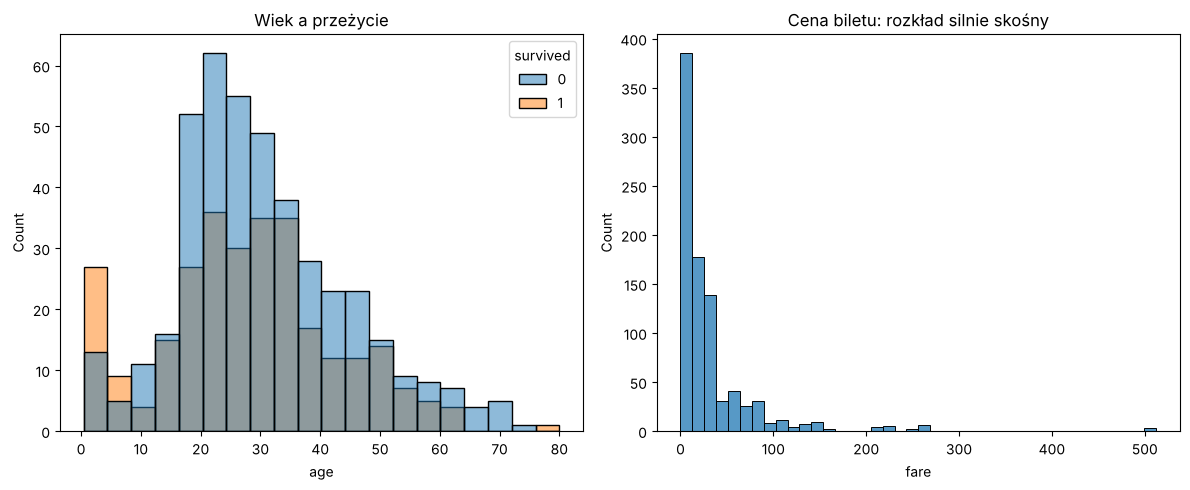

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="age", hue="survived", bins=20, ax=axes[0])
axes[0].set_title("Wiek a przeżycie")
sns.histplot(data=df, x="fare", bins=40, ax=axes[1])
axes[1].set_title("Cena biletu: rozkład silnie skośny")
fig.tight_layout()
plt.show()

**Wnioski z EDA, które zmieniają nasze dalsze decyzje:**
- klasy są niezbalansowane (ok. 62% / 38%) → potrzebny **baseline**, a accuracy trzeba porównywać z nim,
- `age` ma ok. 20% braków, `embarked` 2 braki → **imputacja** (`age`: mediana, `embarked`: najczęstsza wartość),
- `fare` jest silnie skośna (skośność ok. 4.8) → do imputacji mediana, nie średnia,
- `sex` i `embarked` są tekstowe → **kodowanie** (one-hot),
- `age` (0–80) i `fare` (0–512) mają różne skale → **standaryzacja**,
- `sex` i `pclass` silnie wiążą się z przeżyciem → to będą ważne cechy.

### Usunięcie zbędnych kolumn

| Kolumna | Dlaczego usuwamy |
|---|---|
| `alive` | to **etykieta zapisana tekstem** (yes/no) – model „widziałby odpowiedź”, czyli wyciek danych |
| `deck` | 77% braków – uzupełnianie byłoby głównie zgadywaniem |
| `class`, `embark_town` | duplikaty `pclass` i `embarked` |
| `who`, `adult_male`, `alone` | cechy wyliczone z innych kolumn; na razie pomijamy (można je dodać przy iteracji) |

In [8]:
df = df.drop(columns=["alive", "deck", "class", "embark_town", "who", "adult_male", "alone"])
print(df.columns.tolist())

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']


> **Sprawdź się:** Co by się stało, gdybyśmy zostawili kolumnę `alive`?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Model nauczyłby się, że `alive == 'yes'` oznacza `survived == 1` i miałby accuracy 100% – bez żadnej wartości, bo przy nowym pasażerze tej informacji nie mamy. To klasyczny wyciek danych (*data leakage*).
>
> </details>

---
## 3. Podział train / test

Dzielimy dane **przed** jakimkolwiek krokiem, który uczy się z danych (imputacja, skalowanie, model). Zbiór testowy udaje „nowych pasażerów”.

In [9]:
features = ["pclass", "sex", "age", "fare", "embarked", "sibsp", "parch"]
target = "survived"

X_train, X_test, y_train, y_test = train_test_split(
    df[features], df[target],
    test_size=0.25,        # 25% do testu
    stratify=df[target],   # ten sam odsetek ocalałych w obu częściach
    random_state=42,       # powtarzalny podział
)
print(X_train.shape, X_test.shape)
print(f"ocalali: train {y_train.mean():.3f}, test {y_test.mean():.3f}")

(668, 7) (223, 7)
ocalali: train 0.383, test 0.386


> **Sprawdź się:** Po co `stratify`?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Przy losowym podziale odsetek ocalałych w teście mógłby przypadkiem wyjść np. 33% albo 43%. `stratify` gwarantuje te same proporcje klas w obu częściach, więc ocena jest stabilniejsza.
>
> </details>

---
## 4. Przygotowanie danych: jak działa scikit-learn

Każdy obiekt scikit-learn ma ten sam, prosty interfejs:

| Rodzaj | Metody | Przykład |
|---|---|---|
| **estymator** – szacuje parametry z danych | `fit(X)` lub `fit(X, y)` | każdy obiekt poniżej |
| **transformator** – przekształca dane | `transform(X)`, `fit_transform(X)` | `SimpleImputer`, `StandardScaler`, `OneHotEncoder` |
| **predyktor** – przewiduje | `predict(X)`, `score(X, y)` | `LogisticRegression`, `DummyClassifier` |

- **hiperparametry** podajemy w konstruktorze (np. `strategy="median"`) i są dostępne jako atrybuty (`imputer.strategy`),
- **wyuczone parametry** pojawiają się po `fit` i mają **podkreślnik na końcu** (`imputer.statistics_`, `scaler.mean_`).

### 4a. Braki: `SimpleImputer`

In [10]:
imputer = SimpleImputer(strategy="median")   # hiperparametr
imputer.fit(X_train[["age", "fare"]])        # fit: liczy medianę - TYLKO na train

print("hiperparametr:", imputer.strategy)
print("wyuczone mediany:", imputer.statistics_)        # parametr wyuczony -> podkreślnik

age_fare_test = imputer.transform(X_test[["age", "fare"]])   # transform: wstawia TE SAME mediany do testu
print("braki w teście po transform:", np.isnan(age_fare_test).sum())

hiperparametr: median
wyuczone mediany: [29.     13.8604]
braki w teście po transform: 0


### 4b. Kodowanie zmiennych tekstowych: `OneHotEncoder`
Model liczy $w_1 x_1 + w_2 x_2 + \dots$ – tekstu `"male"` nie da się pomnożyć przez wagę:

In [11]:
try:
    LogisticRegression().fit(X_train[["sex"]], y_train)
except ValueError as e:
    print("ValueError:", e)

ValueError: could not convert string to float: 'female'


In [12]:
encoder = OneHotEncoder(handle_unknown="ignore")
encoder.fit(X_train[["embarked"]].dropna())
print("kategorie:", encoder.categories_)

przyklad = pd.DataFrame({"embarked": ["S", "C", "Q"]})
pd.DataFrame(encoder.transform(przyklad).toarray(), index=przyklad["embarked"],
             columns=encoder.get_feature_names_out())

kategorie: [array(['C', 'Q', 'S'], dtype=object)]


,embarked_C,embarked_Q,embarked_S
embarked,,,
S,0.0,0.0,1.0
C,1.0,0.0,0.0
Q,0.0,1.0,0.0


> **Sprawdź się:** Dlaczego nie zakodować portów jako C = 0, Q = 1, S = 2?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Takie liczby narzucają porządek i równe odstępy: model uznałby, że Q leży „pomiędzy” C i S, a S jest „dwa razy dalej” od C. Port to zmienna nominalna (bez porządku), więc każda kategoria dostaje własną kolumnę 0/1. `pclass` zostawiamy jako liczbę, bo klasy mają naturalny porządek (1 < 2 < 3).
>
> </details>

### 4c. Skalowanie: `StandardScaler`
Wiek (0–80) i cena biletu (0–512) są w różnych skalach. Standaryzacja $x' = (x - \bar{x}) / s$ sprowadza każdą cechę do średniej 0 i odchylenia 1.

In [13]:
# kroki łączą się: wynik imputera (bez braków) trafia do scalera
age_fare_train = imputer.transform(X_train[["age", "fare"]])
scaler = StandardScaler().fit(age_fare_train)        # fit: liczy średnią i odchylenie - TYLKO na train
print("średnie:", scaler.mean_.round(2))              # wyuczone parametry -> podkreślnik
print("odchylenia:", scaler.scale_.round(2))

age_fare_test_s = scaler.transform(age_fare_test)    # te same parametry dla testu
print("pierwsze 3 wiersze testu po skalowaniu:\n", age_fare_test_s[:3].round(2))

średnie: [29.75 31.18]
odchylenia: [12.95 47.42]
pierwsze 3 wiersze testu po skalowaniu:
 [[ 0.02 -0.49]
 [-0.68 -0.49]
 [-1.14 -0.5 ]]


### 4d. Wszystko razem: `ColumnTransformer` + `Pipeline`
Robienie tych kroków ręcznie jest żmudne i łatwo o błąd (np. `fit` na teście). **Pipeline** składa je w jeden estymator:

- `ColumnTransformer` – **różne kroki dla różnych kolumn**: liczby → imputacja medianą + skalowanie, kategorie → imputacja najczęstszą wartością + one-hot,
- `make_pipeline(przygotowanie, model)` – po przygotowaniu dane trafiają do modelu.

Cały pipeline zachowuje się jak jeden model: ma `fit`, `predict` i `score`.

In [14]:
num_features = ["pclass", "age", "fare", "sibsp", "parch"]
cat_features = ["sex", "embarked"]

przygotowanie = ColumnTransformer([
    ("liczby",    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_features),
    ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                OneHotEncoder(handle_unknown="ignore")),             cat_features),
])

model = make_pipeline(przygotowanie, LogisticRegression())
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('liczby', ...), ('kategorie', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshol

---
## 5. Trenowanie

Jedno `fit` uruchamia po kolei `fit` każdego kroku – **zawsze na danych treningowych**.

In [15]:
model.fit(X_train, y_train)

# inspekcja: wyuczone parametry są dostępne wewnątrz pipeline'u
liczby = model.named_steps["columntransformer"].named_transformers_["liczby"]
print("mediany (z train):", liczby.named_steps["simpleimputer"].statistics_)

nazwy = model.named_steps["columntransformer"].get_feature_names_out()
wagi = pd.Series(model.named_steps["logisticregression"].coef_[0], index=nazwy).sort_values()
wagi.round(3)

mediany (z train): [ 3.     29.     13.8604  0.      0.    ]


kategorie__sex_male     -1.313
liczby__pclass          -0.928
liczby__age             -0.528
kategorie__embarked_S   -0.335
liczby__sibsp           -0.253
liczby__parch           -0.033
kategorie__embarked_C    0.019
liczby__fare             0.129
kategorie__embarked_Q    0.294
kategorie__sex_female    1.291
dtype: float64

> **Sprawdź się:** Która cecha najbardziej zwiększa, a która najbardziej zmniejsza szansę przeżycia?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Największa dodatnia waga: `sex_female`, największe ujemne: `sex_male` i `pclass` (wyższy numer klasy = gorzej). Zgadza się z EDA. Porównywanie wag ma sens, bo cechy liczbowe są wystandaryzowane.
>
> </details>

---
## 6. Predykcja

`predict` przepuszcza nowe dane przez **te same kroki z zapamiętanymi parametrami** (mediany i średnie z train) i zwraca decyzje. `predict_proba` zwraca prawdopodobieństwa.

In [16]:
y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

podglad = X_test.head(5).copy()
podglad["p(przeżycie)"] = proba[:5].round(2)
podglad["predykcja"] = y_pred[:5]
podglad["prawda"] = y_test.head(5).values
podglad

,pclass,sex,age,fare,embarked,sibsp,parch,p(przeżycie),predykcja,prawda
157,3,male,30.0,8.0500,S,0,0,0.08,0,0
501,3,female,21.0,7.7500,Q,0,0,0.77,1,0
352,3,male,15.0,7.2292,C,1,1,0.15,0,0
82,3,female,NaN,7.7875,Q,0,0,0.71,1,1
683,3,male,14.0,46.9000,S,5,2,0.05,0,0


---
## 7. Ewaluacja

`score(X, y)` to szybka ocena: **dla klasyfikatora zwraca accuracy**, dla regresora $R^2$. Zawsze porównujemy z **baseline'em**: `DummyClassifier` to „model”, który zawsze zwraca najczęstszą klasę – ma ten sam interfejs co każdy estymator.

In [17]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

wyniki = pd.Series({
    "baseline (nikt nie przeżył)": baseline.score(X_test, y_test),
    "reguła: kobieta → 1": ((X_test["sex"] == "female").astype(int) == y_test).mean(),
    "pipeline – train": model.score(X_train, y_train),
    "pipeline – test": model.score(X_test, y_test),
})
wyniki.round(3)

baseline (nikt nie przeżył)    0.614
reguła: kobieta → 1            0.767
pipeline – train               0.811
pipeline – test                0.771
dtype: float64

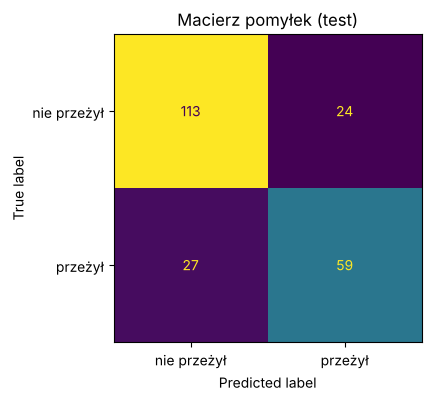

              precision    recall  f1-score   support

 nie przeżył      0.807     0.825     0.816       137
     przeżył      0.711     0.686     0.698        86

    accuracy                          0.771       223
   macro avg      0.759     0.755     0.757       223
weighted avg      0.770     0.771     0.771       223



In [18]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["nie przeżył", "przeżył"]).plot(ax=ax, colorbar=False)
ax.set_title("Macierz pomyłek (test)")
plt.show()

print(classification_report(y_test, y_pred, target_names=["nie przeżył", "przeżył"], digits=3))

> **Sprawdź się:** Wynik na train jest wyższy niż na test. Który raportujemy i dlaczego?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Wynik testowy (ok. 0.77). Model widział dane treningowe, więc ocena na nich jest zawyżona. Test udaje nowe dane – tylko on mówi, jak model poradzi sobie w praktyce.
>
> </details>

> **Sprawdź się:** Pipeline jest lepszy od reguły „kobieta → 1” tylko o ok. 0.5 p.p. Co z tego wynika?
>
> <details><summary>pokaż odpowiedź</summary>
>
> W zbiorze testowym (223 osoby) to różnica jednej osoby, czyli w granicach przypadku. Na tych danych model w dużej mierze „odkrył” regułę płci. Wniosek: zawsze porównujemy z prostymi punktami odniesienia, a nie tylko z zerem.
>
> </details>

---
## 8. Iteracja

Pipeline ułatwia eksperymenty: zmieniamy jeden element i sprawdzamy efekt **na tym samym podziale**. Tu sprawdzamy dwa pomysły:
- `SimpleImputer(..., add_indicator=True)` – dodaje kolumnę-flagę „wiek był brakujący”,
- model **bez płci** – jak ważna jest ta jedna cecha?

In [19]:
def zbuduj(num, cat, add_indicator=False):
    przyg = ColumnTransformer([
        ("liczby", make_pipeline(SimpleImputer(strategy="median", add_indicator=add_indicator), StandardScaler()), num),
        ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat),
    ])
    return make_pipeline(przyg, LogisticRegression())


warianty = {
    "pełny": zbuduj(num_features, cat_features),
    "+ flaga braku wieku": zbuduj(num_features, cat_features, add_indicator=True),
    "bez płci": zbuduj(num_features, ["embarked"]),
}
pd.Series({nazwa: m.fit(X_train, y_train).score(X_test, y_test) for nazwa, m in warianty.items()}).round(3)

pełny                  0.771
+ flaga braku wieku    0.785
bez płci               0.682
dtype: float64

> **Sprawdź się:** Czy wybieranie najlepszego wariantu po wyniku na zbiorze testowym jest w porządku?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Nie do końca: jeśli porównamy wiele wariantów i wybierzemy najlepszy na teście, to test przestaje być „nowymi danymi” – dopasowaliśmy decyzję do niego. Poprawnie robi się to na osobnym zbiorze walidacyjnym albo walidacją krzyżową (kolejne zajęcia). Test zostawiamy na samą końcową ocenę.
>
> </details>

---
## Podsumowanie: lista kontrolna do zadania z pingwinami

1. Wczytaj dane, sprawdź `shape`, `info()`, wybierz etykietę.
2. EDA: rozkład klas, braki, skale, zależności (tabela, wykres). Zapisz wnioski i decyzje.
3. Usuń to, co zbędne (wiersze/kolumny) i **uzasadnij**.
4. Podział train/test **przed** przygotowaniem danych (`stratify`, `random_state`).
5. `ColumnTransformer`: liczby → imputer + scaler, kategorie → imputer + one-hot.
6. `make_pipeline(przygotowanie, model)`, `fit` na train.
7. Ewaluacja na test: `score`, baseline (`DummyClassifier`), macierz pomyłek, `classification_report`.
8. Iteracja: zmień jedną rzecz i porównaj.